# Historical results and analysis

The university team compared supervised Deformable DETR with four teacher–student recipes on a separate five-class PCB dataset. The dataset had 2,518 training, 840 validation, and 838 test images. The 5% and 10% settings used 126 and 252 labeled training images. The remaining training images were available for pseudo-labeling.

Each run used seed 42 and selected its checkpoint on validation AP. The chart replots ten saved test scores over IoU thresholds from 0.50 to 0.95. It was generated on CPU from the verified aggregate CSV and saved here for viewing without execution.

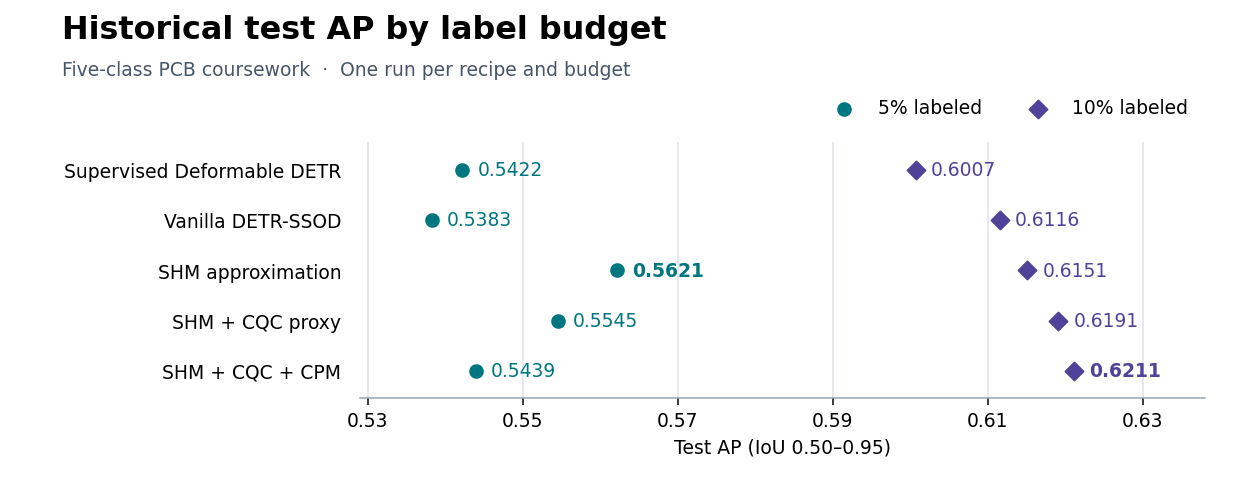

In [1]:
from base64 import b64encode
from pathlib import Path

from IPython.display import display

relative = Path("reports/semi_supervised_research/figures/historical_test_ap.png")
figure = next(
    (path / relative for path in (Path.cwd(), *Path.cwd().parents) if (path / relative).is_file()),
    None,
)
if figure is None:
    raise FileNotFoundError("Open this notebook from within the repository.")
display({"image/png": b64encode(figure.read_bytes()).decode("ascii")}, raw=True)

SHM led at 5% labeling, where vanilla SSOD trailed the supervised baseline. The combined SHM + CQC + CPM recipe led at 10%. The two columns compare complete recipes on the same historical test split.

## Scores and training implementations

| Training implementation | 5% labeled | 10% labeled |
| --- | ---: | ---: |
| [Supervised Deformable DETR](01_supervised_deformable_detr.ipynb) | 0.5422 | 0.6007 |
| [Vanilla DETR-SSOD](02_vanilla_detr_ssod.ipynb) | 0.5383 | 0.6116 |
| [SHM approximation](03_shm_approximation.ipynb) | 0.5621 | 0.6151 |
| [SHM + CQC proxy](04_shm_cqc_proxy.ipynb) | 0.5545 | 0.6191 |
| [SHM + CQC + CPM](05_shm_cqc_cpm.ipynb) | 0.5439 | 0.6211 |

The linked notebooks are sanitized 10% implementations for code inspection. Their training cells carry no saved outputs. The results above came from the original 5% and 10% runs.

## How to interpret the comparison

- Each recipe and label budget has one seed. Pseudo-label candidate generation changes with CQC, and unlabeled sampling changes with CPM. The measured differences combine these changes with the added methods.
- The 10% SHM-containing checkpoints were selected at epochs 115, 120, and 120, during target duplication. Their test scores describe those checkpoints.
- The filename audit found 587 candidate train/test image families. Board-level overlap remains unresolved. [Split audit](../../reports/semi_supervised_research/split_audit.json)

## Evidence and access

The result CSV records the original notebook, output location, and SHA-256 for each run. The test AP figure uses the same ten values previously reported publicly. Per-epoch validation curves are available for authorized local review, pending coursework disclosure clearance. The analysis here renders the saved results without training or inference.

[Result CSV and provenance](../../reports/semi_supervised_research/historical_results.csv) · [Research guide](../../docs/semi_supervised_research.md) · [Local verification and plot regeneration](../../docs/reproducibility.md#verify-the-historical-detr-runs)